In [42]:
import warnings, os, joblib
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/drive/MyDrive/DSA_B11/Exit Exam/G1.csv")

print("Shape:", df.shape)
display(df.head())

Shape: (500, 30)


,Response_ID,Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,...,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore,Best_Shopping_Mode
0,1,01/08/2026 12:30:25,20,Male,NaN,Philippines,"Under $1,000",Equal mix,Often,Physical stores,...,Never,Under $50,Digital wallet,"Yes, occasionally",6.0,7.0,2.0,More variety,No delivery wait,Online
1,2,21/06/2026 13:52:02,24,Male,Employed part-time,Brazil,"Under $1,000",In-store only,Often,Local e-commerce,...,Often,Under $50,Digital wallet,"No, never",5.0,8.0,3.0,NaN,Try product before buying,Offline
2,3,15/08/2026 04:24:18,22,Female,Student,India,"Under $1,000",Equal mix,Always,Local e-commerce,...,Sometimes,$150-300,Credit Card,"No, never",7.0,6.0,2.0,Better prices,Trust,Online
3,4,23/06/2026 21:24:21,20,Male,Student,NaN,"Under $1,000",In-store only,Occasionally,Brand websites,...,Never,Under $50,Debit Card,"No, never",8.0,7.0,3.0,Better prices,Try product before buying,Equal / both
4,5,20/08/2026 16:24:47,41,Male,Employed full-time,United States,"$1,000-3,000",Equal mix,Occasionally,NaN,...,Sometimes,$50-150,Debit Card,"No, never",6.0,8.0,2.0,Convenience,Trust,Equal / both


In [43]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
df.info()

print("\nSummary:")
display(df.describe(include="all").T)

print("\nMissing values:")
missing = pd.DataFrame({
    "count": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(2)
})
display(missing[missing["count"] > 0].sort_values("percent", ascending=False))

print("Exact duplicate rows:", df.duplicated().sum())

for col in df.select_dtypes(include=["object", "category"]).columns:
    print(f"\n{col} — sample unique values:")
    print(df[col].value_counts(dropna=False).head(15))

Shape: (500, 30)

Columns: ['Response_ID', 'Timestamp', 'Age', 'Gender', 'Occupation_Status', 'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where', 'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device', 'Top_Spending_Category', 'Review_Influence_Score', 'Social_Ads_Influence_Score', 'Price_Comparison_Frequency', 'Discount_Importance_Score', 'Follows_Brands_On_Social', 'Likely_To_Buy_After_Ad_Score', 'Makes_Shopping_List', 'Impulse_Purchase_Frequency', 'Return_Frequency', 'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method', 'Uses_BNPL_Installments', 'Online_Shopping_Satisfaction_Score', 'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency', 'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 30 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Response_ID,500.0,NaN,NaN,NaN,250.5,144.481833,1.0,125.75,250.5,375.25,500.0
Timestamp,500,500,01/08/2026 12:30:25,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,478,43,21,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,484,3,Male,256,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Occupation_Status,479,5,Student,238,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country_Region,480,18,India,66,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Monthly_Income_Range,479,4,"Under $1,000",257,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Shop_Most_Where,484,3,Equal mix,248,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Online_Shopping_Frequency,481,4,Occasionally,240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Preferred_Platform,486,4,Global marketplace (Amazon etc.),141,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


,count,percent
Reason_Prefer_Online,54,10.8
Regret_After_Purchase_Frequency,52,10.4
Best_Shopping_Mode,51,10.2
Trust_In_Online_Reviews_Score,50,10.0
Reason_Prefer_InStore,45,9.0
Online_Shopping_Satisfaction_Score,43,8.6
Price_Comparison_Frequency,26,5.2
Likely_To_Buy_After_Ad_Score,25,5.0
Top_Spending_Category,24,4.8
Makes_Shopping_List,24,4.8


Exact duplicate rows: 0

Timestamp — sample unique values:
Timestamp
01/08/2026 12:30:25    1
21/06/2026 13:52:02    1
15/08/2026 04:24:18    1
23/06/2026 21:24:21    1
20/08/2026 16:24:47    1
11/07/2026 00:16:12    1
24/07/2026 23:10:04    1
19/07/2026 23:47:44    1
20/07/2026 15:49:25    1
30/07/2026 11:38:27    1
07/07/2026 17:51:14    1
20/08/2026 19:14:20    1
17/08/2026 21:17:14    1
14/07/2026 14:53:39    1
24/08/2026 18:59:02    1
Name: count, dtype: int64

Age — sample unique values:
Age
21     67
20     46
18     45
22     35
19     28
NaN    22
24     20
23     19
16     18
31     15
17     15
32     14
30     13
29     13
25     13
Name: count, dtype: int64

Gender — sample unique values:
Gender
Male                 256
Female               177
Prefer not to say     51
NaN                   16
Name: count, dtype: int64

Occupation_Status — sample unique values:
Occupation_Status
Student               238
Employed full-time    118
Employed part-time     71
Self-employed    

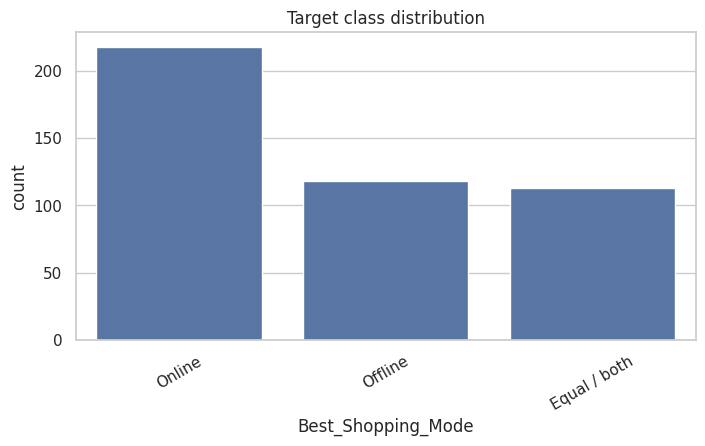

Best_Shopping_Mode
Online          218
Offline         118
Equal / both    113
Name: count, dtype: int64
Class proportions:
Best_Shopping_Mode
Online          0.486
Offline         0.263
Equal / both    0.252
Name: proportion, dtype: float64


In [44]:
TARGET = 'Best_Shopping_Mode'

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x=TARGET, order=df[TARGET].value_counts().index)
plt.title("Target class distribution")
plt.xticks(rotation=30)
plt.show()

print(df[TARGET].value_counts())
print("Class proportions:")
print(df[TARGET].value_counts(normalize=True).round(3))

##Is  the dataset balanced with respect to shopping mode?

It is **not balanced** among the 449 responses with a recorded `Best_Shopping_Mode`:

| Mode | Responses | Share of labeled responses |
| --- | --- | --- |
| Online | 218 | 48.6% |
| Offline | 118 | 26.3% |
| Equal / both | 113 | 25.2% |



Online is the largest class, while Offline and Equal/Both are similar in size. The target is missing for 51 of 500 respondents (10.2%); those rows can’t be used as labeled examples for supervised training.

##Which demographic group appears to dominate the survey?

Students are the largest reported occupation group: 238 of 479 responses with occupation data (about 49.7%). The respondents also skew male (256 of 484; 52.9%), toward ages 18–24 (260 of 478 with age data; 54.4%), and toward the Under $1,000 income range (257 of 479; 53.7%). India is the most represented country, with 66 of 480 responses. These are separate marginal counts—the data shown doesn’t establish that one combined group, such as young male students in India, dominates.

##What initial business insights can you infer from the data?

The preferred mode and current shopping behavior may not be identical: “Equal mix” is the most common `Shop_Most_Where` response (248), even though Online leads `Best_Shopping_Mode`. Online’s most cited advantages are variety (170) and convenience (157); in-store’s top cited advantage is trying products before buying (145). Price comparison (mean 4.14/5) and discount importance (3.82/5) are relatively high, suggesting price and promotions may matter. Smartphone use is common (315), and online satisfaction averages 7.13/10.

In [45]:
DROP_COLUMNS = ['Response_ID', 'Timestamp']

df = df.copy()

# Optional safe text cleanup
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].str.strip()

# Remove exact duplicates only if appropriate for the dataset
df = df.drop_duplicates().copy()

if TARGET not in df.columns:
    raise ValueError(f"Set TARGET correctly. Available columns: {df.columns.tolist()}")

df = df.dropna(subset=[TARGET]).copy()

existing_drop = [c for c in DROP_COLUMNS if c in df.columns and c != TARGET]
df = df.drop(columns=existing_drop)

print("Shape after basic cleaning:", df.shape)
print("Target classes:")
display(df[TARGET].value_counts(dropna=False).to_frame("count"))
display((df[TARGET].value_counts(normalize=True) * 100).round(2).to_frame("percent"))

Shape after basic cleaning: (449, 28)
Target classes:


,count
Best_Shopping_Mode,
Online,218
Offline,118
Equal / both,113


,percent
Best_Shopping_Mode,
Online,48.55
Offline,26.28
Equal / both,25.17


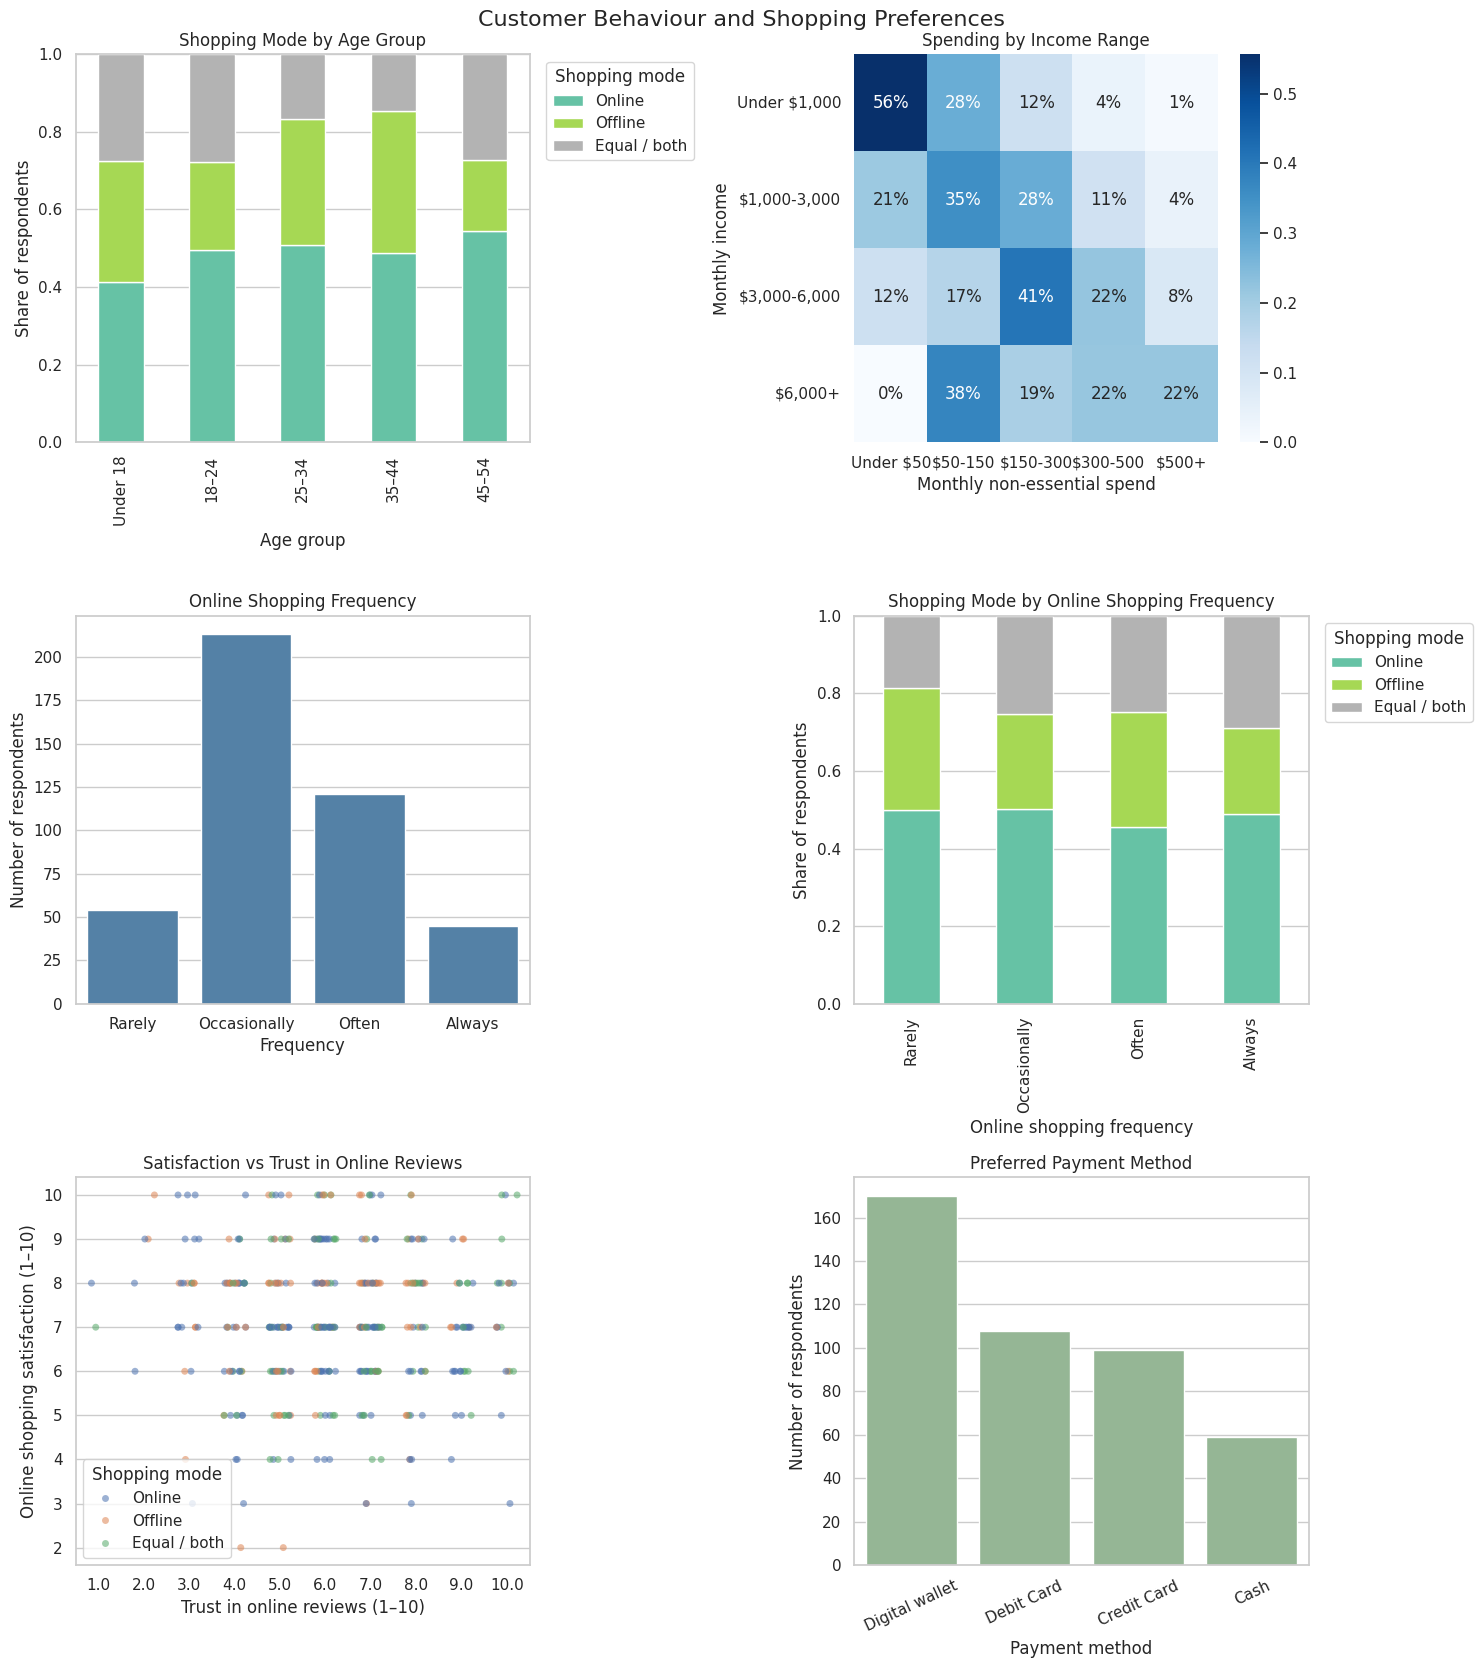

In [46]:
sns.set_theme(style="whitegrid")

# Keep category order consistent across charts
modes = ["Online", "Offline", "Equal / both"]
frequencies = ["Rarely", "Occasionally", "Often", "Always"]
income_order = ["Under $1,000", "$1,000-3,000", "$3,000-6,000", "$6,000+"]
spending_order = ["Under $50", "$50-150", "$150-300", "$300-500", "$500+"]

# Make numeric fields numeric; invalid or missing values become NaN
df = df.copy()
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["Online_Shopping_Satisfaction_Score"] = pd.to_numeric(
    df["Online_Shopping_Satisfaction_Score"], errors="coerce"
)
df["Trust_In_Online_Reviews_Score"] = pd.to_numeric(
    df["Trust_In_Online_Reviews_Score"], errors="coerce"
)

# Create age bands for easier comparison
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 17, 24, 34, 44, 54, 120],
    labels=["Under 18", "18–24", "25–34", "35–44", "45–54", "55+"],
    include_lowest=True
)

fig, axes = plt.subplots(3, 2, figsize=(15, 17))
fig.suptitle("Customer Behaviour and Shopping Preferences", fontsize=16)

# 1. Age group vs shopping mode — percentage within each age group
data = df.dropna(subset=["Age_Group", "Best_Shopping_Mode"])
table = pd.crosstab(data["Age_Group"], data["Best_Shopping_Mode"], normalize="index")
table = table.reindex(columns=modes, fill_value=0)
table.plot(kind="bar", stacked=True, ax=axes[0, 0], colormap="Set2")
axes[0, 0].set(title="Shopping Mode by Age Group", xlabel="Age group",
               ylabel="Share of respondents", ylim=(0, 1))
axes[0, 0].legend(title="Shopping mode", bbox_to_anchor=(1.02, 1))

# 2. Income vs non-essential spending — percentage within each income group
data = df.dropna(subset=["Monthly_Income_Range", "Avg_Monthly_Spend_NonEssentials"])
table = pd.crosstab(
    data["Monthly_Income_Range"], data["Avg_Monthly_Spend_NonEssentials"],
    normalize="index"
)
table = table.reindex(index=income_order, columns=spending_order, fill_value=0)
sns.heatmap(table, annot=True, fmt=".0%", cmap="Blues", ax=axes[0, 1])
axes[0, 1].set(title="Spending by Income Range", xlabel="Monthly non-essential spend",
               ylabel="Monthly income")

# 3. Online shopping frequency — response counts
counts = df["Online_Shopping_Frequency"].value_counts().reindex(frequencies, fill_value=0)
sns.barplot(x=counts.index, y=counts.values, color="steelblue", ax=axes[1, 0])
axes[1, 0].set(title="Online Shopping Frequency", xlabel="Frequency",
               ylabel="Number of respondents")

# 4. Shopping frequency vs preferred mode — percentage within each frequency group
data = df.dropna(subset=["Online_Shopping_Frequency", "Best_Shopping_Mode"])
table = pd.crosstab(
    data["Online_Shopping_Frequency"], data["Best_Shopping_Mode"], normalize="index"
)
table = table.reindex(index=frequencies, columns=modes, fill_value=0)
table.plot(kind="bar", stacked=True, ax=axes[1, 1], colormap="Set2")
axes[1, 1].set(title="Shopping Mode by Online Shopping Frequency",
               xlabel="Online shopping frequency", ylabel="Share of respondents", ylim=(0, 1))
axes[1, 1].legend(title="Shopping mode", bbox_to_anchor=(1.02, 1))

# 5. Satisfaction vs review-trust score; color shows preferred mode
data = df.dropna(subset=[
    "Online_Shopping_Satisfaction_Score",
    "Trust_In_Online_Reviews_Score",
    "Best_Shopping_Mode"
])
sns.stripplot(
    data=data,
    x="Trust_In_Online_Reviews_Score",
    y="Online_Shopping_Satisfaction_Score",
    hue="Best_Shopping_Mode",
    hue_order=modes,
    jitter=0.25,
    alpha=0.55,
    ax=axes[2, 0]
)
axes[2, 0].set(title="Satisfaction vs Trust in Online Reviews",
               xlabel="Trust in online reviews (1–10)",
               ylabel="Online shopping satisfaction (1–10)")
axes[2, 0].legend(title="Shopping mode")

# 6. Payment method — response counts
counts = df["Preferred_Payment_Method"].value_counts().sort_values(ascending=False)
sns.barplot(x=counts.index, y=counts.values, color="darkseagreen", ax=axes[2, 1])
axes[2, 1].set(title="Preferred Payment Method", xlabel="Payment method",
               ylabel="Number of respondents")
axes[2, 1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

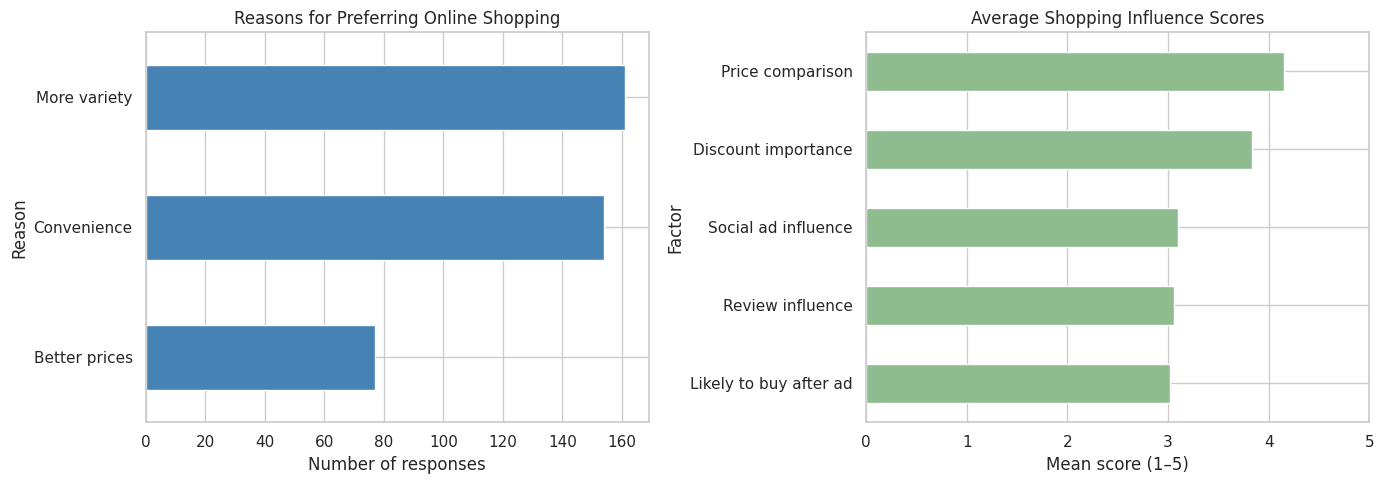

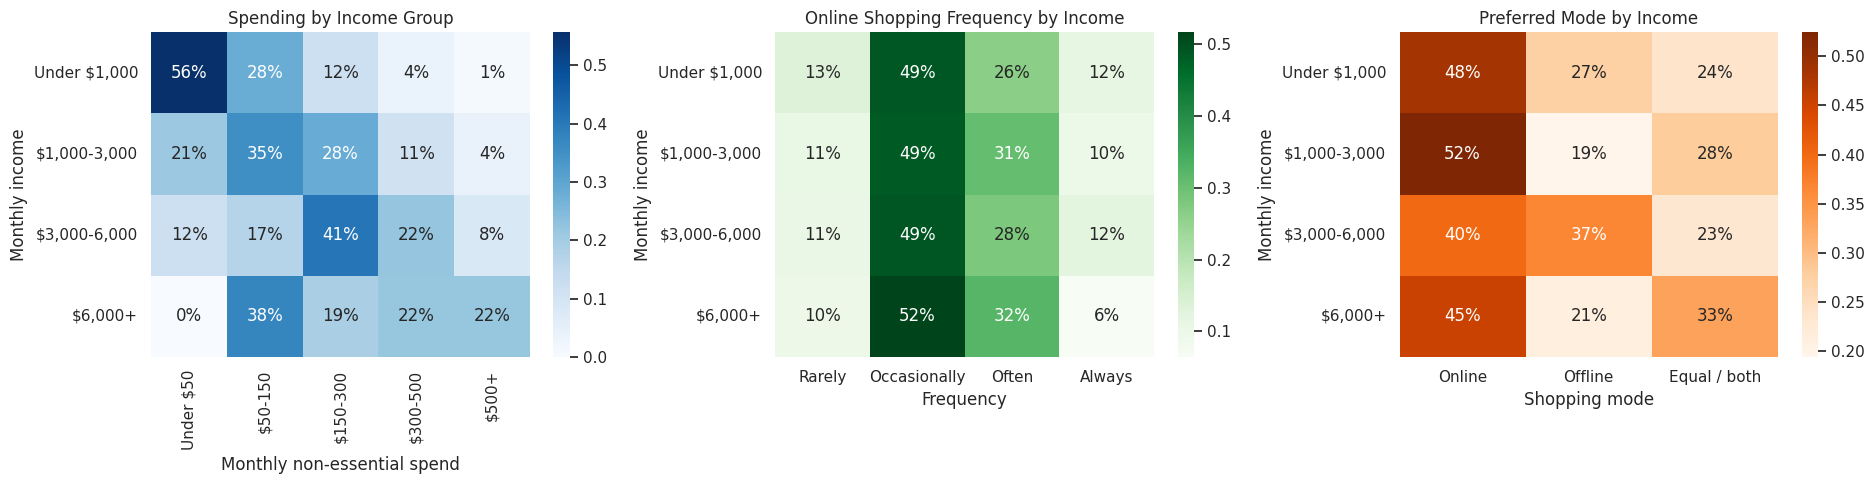

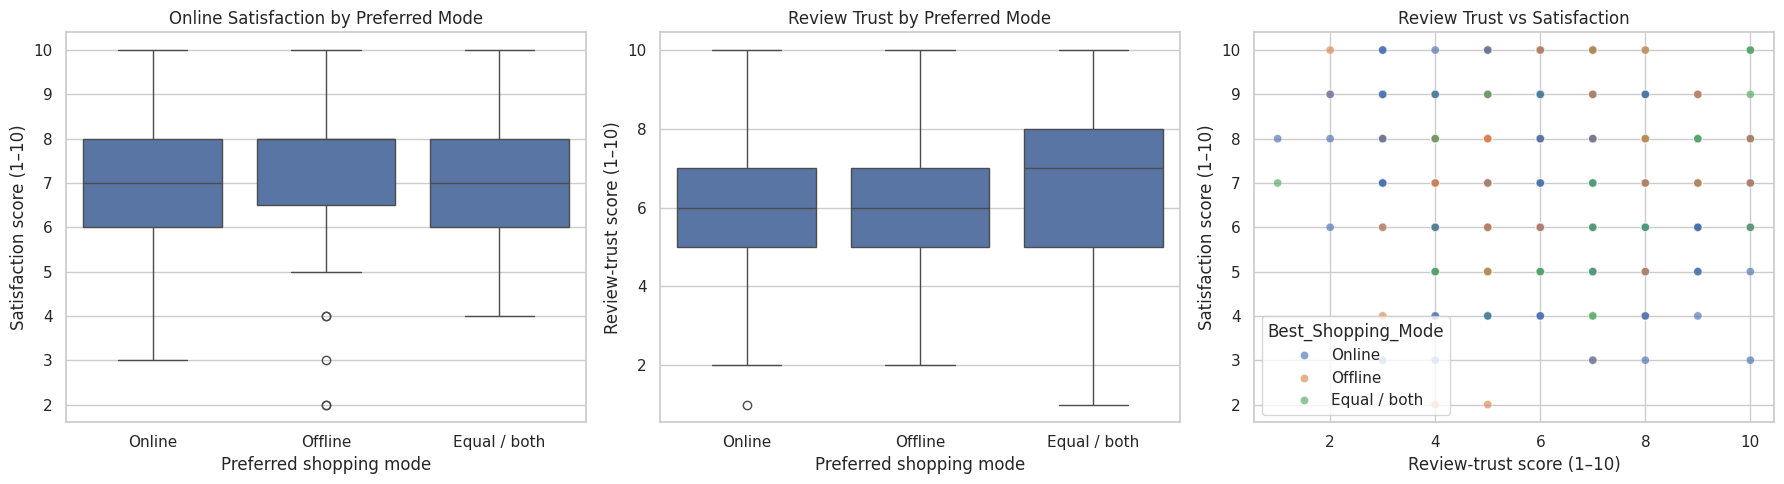

In [47]:
sns.set_theme(style="whitegrid")

df = df.copy()

income_order = ["Under $1,000", "$1,000-3,000", "$3,000-6,000", "$6,000+"]
spending_order = ["Under $50", "$50-150", "$150-300", "$300-500", "$500+"]
frequency_order = ["Rarely", "Occasionally", "Often", "Always"]
mode_order = ["Online", "Offline", "Equal / both"]

# Ensure score columns are numeric
score_columns = [
    "Review_Influence_Score",
    "Social_Ads_Influence_Score",
    "Price_Comparison_Frequency",
    "Discount_Importance_Score",
    "Likely_To_Buy_After_Ad_Score",
    "Online_Shopping_Satisfaction_Score",
    "Trust_In_Online_Reviews_Score",
]
for column in score_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")


# 1. Factors associated with online shopping
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Most selected reasons for preferring online shopping
reasons = (
    df["Reason_Prefer_Online"]
    .dropna()
    .loc[lambda s: s != "Not applicable"]
    .value_counts()
    .sort_values()
)
reasons.plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set(title="Reasons for Preferring Online Shopping",
            xlabel="Number of responses", ylabel="Reason")

# Average self-reported influence scores (all are on a 1–5 scale)
factor_labels = {
    "Review_Influence_Score": "Review influence",
    "Social_Ads_Influence_Score": "Social ad influence",
    "Price_Comparison_Frequency": "Price comparison",
    "Discount_Importance_Score": "Discount importance",
    "Likely_To_Buy_After_Ad_Score": "Likely to buy after ad",
}
means = df[list(factor_labels)].mean().rename(index=factor_labels).sort_values()
means.plot(kind="barh", ax=axes[1], color="darkseagreen")
axes[1].set(title="Average Shopping Influence Scores",
            xlabel="Mean score (1–5)", ylabel="Factor", xlim=(0, 5))

plt.tight_layout()
plt.show()


# 2. Income vs shopping behaviour
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# Income vs spending
data = df.dropna(subset=["Monthly_Income_Range", "Avg_Monthly_Spend_NonEssentials"])
table = pd.crosstab(
    data["Monthly_Income_Range"],
    data["Avg_Monthly_Spend_NonEssentials"],
    normalize="index"
).reindex(index=income_order, columns=spending_order, fill_value=0)

sns.heatmap(table, annot=True, fmt=".0%", cmap="Blues", ax=axes[0])
axes[0].set(title="Spending by Income Group", xlabel="Monthly non-essential spend",
            ylabel="Monthly income")

# Income vs online shopping frequency
data = df.dropna(subset=["Monthly_Income_Range", "Online_Shopping_Frequency"])
table = pd.crosstab(
    data["Monthly_Income_Range"],
    data["Online_Shopping_Frequency"],
    normalize="index"
).reindex(index=income_order, columns=frequency_order, fill_value=0)

sns.heatmap(table, annot=True, fmt=".0%", cmap="Greens", ax=axes[1])
axes[1].set(title="Online Shopping Frequency by Income", xlabel="Frequency",
            ylabel="Monthly income")

# Income vs preferred shopping mode
data = df.dropna(subset=["Monthly_Income_Range", "Best_Shopping_Mode"])
table = pd.crosstab(
    data["Monthly_Income_Range"],
    data["Best_Shopping_Mode"],
    normalize="index"
).reindex(index=income_order, columns=mode_order, fill_value=0)

sns.heatmap(table, annot=True, fmt=".0%", cmap="Oranges", ax=axes[2])
axes[2].set(title="Preferred Mode by Income", xlabel="Shopping mode",
            ylabel="Monthly income")

plt.tight_layout()
plt.show()


# 3. Satisfaction and review trust vs shopping preference
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Satisfaction distribution by preferred mode
data = df.dropna(subset=[
    "Best_Shopping_Mode", "Online_Shopping_Satisfaction_Score"
])
sns.boxplot(
    data=data,
    x="Best_Shopping_Mode",
    y="Online_Shopping_Satisfaction_Score",
    order=mode_order,
    ax=axes[0]
)
axes[0].set(title="Online Satisfaction by Preferred Mode",
            xlabel="Preferred shopping mode", ylabel="Satisfaction score (1–10)")

# Review-trust distribution by preferred mode
data = df.dropna(subset=[
    "Best_Shopping_Mode", "Trust_In_Online_Reviews_Score"
])
sns.boxplot(
    data=data,
    x="Best_Shopping_Mode",
    y="Trust_In_Online_Reviews_Score",
    order=mode_order,
    ax=axes[1]
)
axes[1].set(title="Review Trust by Preferred Mode",
            xlabel="Preferred shopping mode", ylabel="Review-trust score (1–10)")

# Relationship between review trust and satisfaction
data = df.dropna(subset=[
    "Trust_In_Online_Reviews_Score",
    "Online_Shopping_Satisfaction_Score",
    "Best_Shopping_Mode"
])
sns.scatterplot(
    data=data,
    x="Trust_In_Online_Reviews_Score",
    y="Online_Shopping_Satisfaction_Score",
    hue="Best_Shopping_Mode",
    hue_order=mode_order,
    alpha=0.65,
    ax=axes[2]
)
axes[2].set(title="Review Trust vs Satisfaction",
            xlabel="Review-trust score (1–10)",
            ylabel="Satisfaction score (1–10)")

plt.tight_layout()
plt.show()

,Feature,Min,Max,IQR lower bound,IQR upper bound,Flagged count
0,Age,16.0,50.0,5.0,45.0,9
1,Review_Influence_Score,1.0,5.0,-1.0,7.0,0
2,Social_Ads_Influence_Score,1.0,5.0,-1.0,7.0,0
3,Price_Comparison_Frequency,1.0,5.0,2.5,6.5,26
4,Discount_Importance_Score,1.0,5.0,0.0,8.0,0
5,Likely_To_Buy_After_Ad_Score,1.0,5.0,-1.0,7.0,0
6,Impulse_Purchase_Frequency,1.0,5.0,0.5,4.5,27
7,Online_Shopping_Satisfaction_Score,2.0,10.0,3.0,11.0,2
8,Trust_In_Online_Reviews_Score,1.0,10.0,2.0,10.0,2
9,Regret_After_Purchase_Frequency,1.0,4.0,-2.0,6.0,0


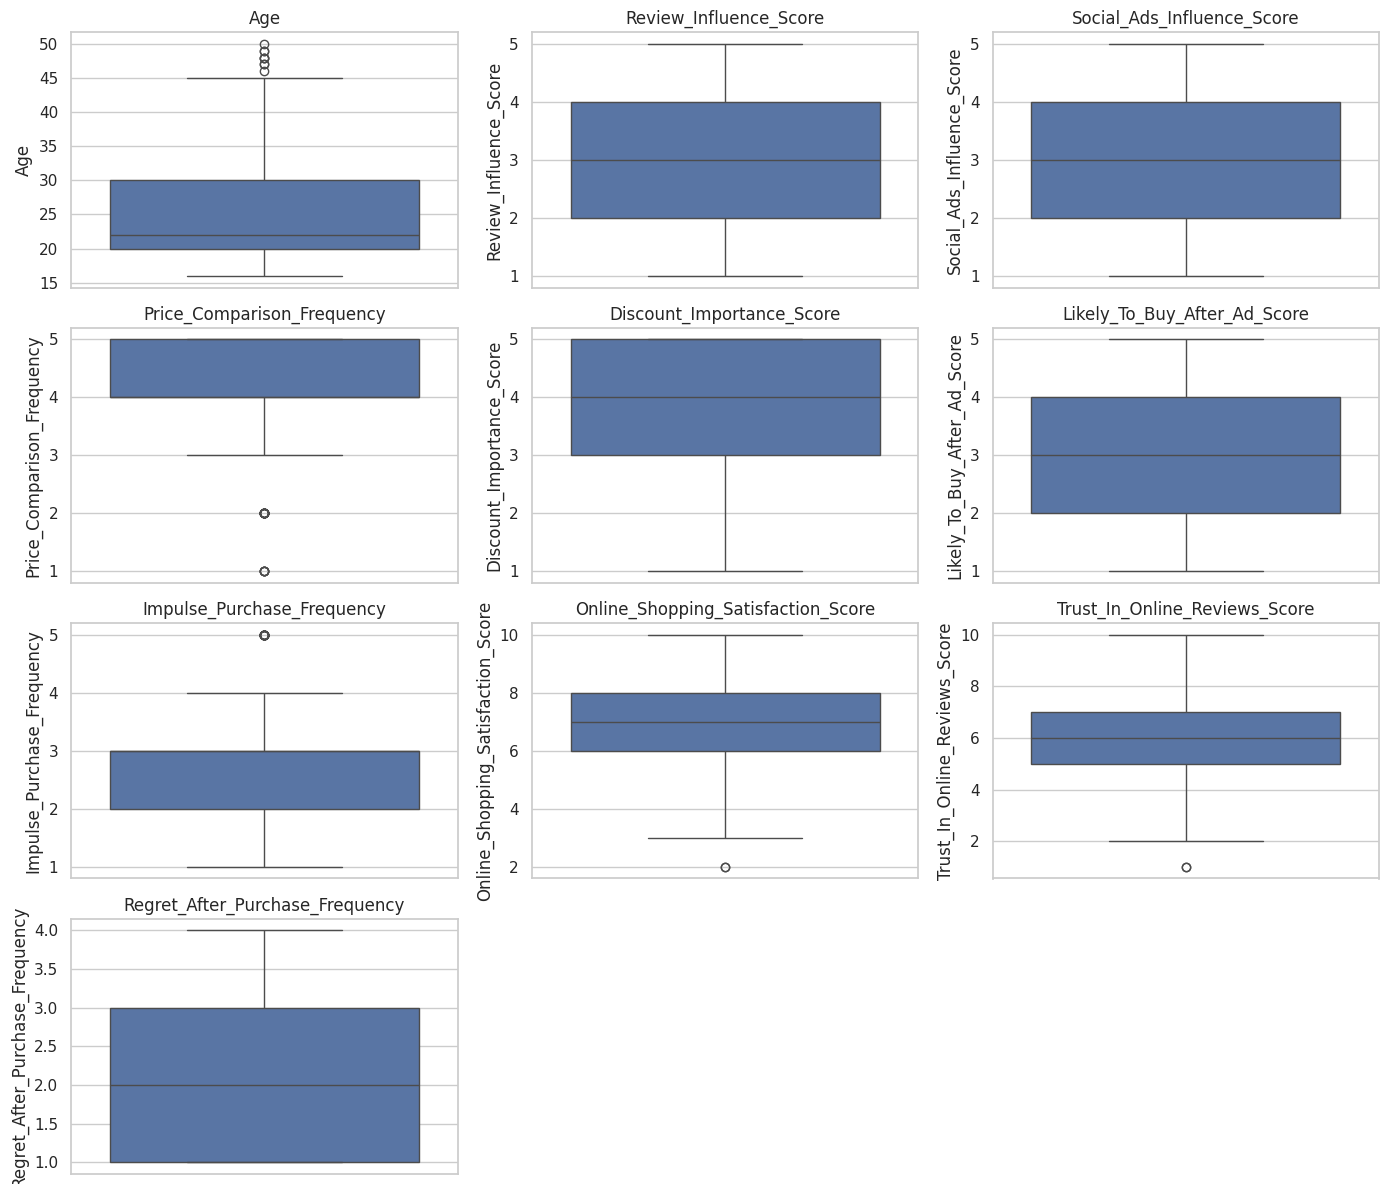

In [48]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = df.copy()

numeric_columns = [
    "Age",
    "Review_Influence_Score",
    "Social_Ads_Influence_Score",
    "Price_Comparison_Frequency",
    "Discount_Importance_Score",
    "Likely_To_Buy_After_Ad_Score",
    "Impulse_Purchase_Frequency",
    "Online_Shopping_Satisfaction_Score",
    "Trust_In_Online_Reviews_Score",
    "Regret_After_Purchase_Frequency",
]
numeric_columns = [c for c in numeric_columns if c in df.columns]

# Age is stored as text in the dataset.
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

# IQR flags show unusual values; they do not prove an error.
outlier_rows = []
for column in numeric_columns:
    values = pd.to_numeric(df[column], errors="coerce").dropna()
    if values.empty:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flagged = values[(values < lower) | (values > upper)]

    outlier_rows.append({
        "Feature": column,
        "Min": values.min(),
        "Max": values.max(),
        "IQR lower bound": lower,
        "IQR upper bound": upper,
        "Flagged count": len(flagged),
    })

display(pd.DataFrame(outlier_rows))

# Inspect each feature on its own scale.
fig, axes = plt.subplots(4, 3, figsize=(14, 12))
for ax, column in zip(axes.flat, numeric_columns):
    sns.boxplot(y=pd.to_numeric(df[column], errors="coerce"), ax=ax)
    ax.set_title(column)
    ax.set_xlabel("")

for ax in axes.flat[len(numeric_columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

##Which factors appear to influence online shopping the most?
  Respondents most often cited **more variety** (170 answers) and **convenience** (157) as reasons to shop online. Better prices was also mentioned (81). Price comparison and discount importance had fairly high average scores. These are survey responses, not proof of what causes online shopping.

##Do higher income customers exhibit different shopping behaviour?
In the **$6,000+ group**, 45% preferred Online, 33% Equal/Both, and 21% Offline. This suggests a slight preference for Online, but we need the same percentages for other income groups to tell whether higher-income customers behave differently.

##How do customer satisfaction and review trust relate to shopping preferences?
Average satisfaction was **7.13/10** and trust in online reviews was **6.16/10**. The model gave both some predictive importance, but we don’t have satisfaction and trust averages by shopping mode. So we can’t yet say how these scores relate to each preference

In [49]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
TARGET = "Best_Shopping_Mode"

# Exclude rows without a target and remove the target from the inputs.
data = df.dropna(subset=[TARGET]).copy()
y = data[TARGET].astype(str).str.strip()

X = data.drop(
    columns=[
        TARGET,
        "Reason_Prefer_Online",
        "Reason_Prefer_InStore",
    ],
    errors="ignore",
)

# Deterministic type conversion; it does not learn from the data.
if "Age" in X.columns:
    X["Age"] = pd.to_numeric(X["Age"], errors="coerce")

# Split before fitting any imputer, scaler, or encoder.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

In [50]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=3000)),
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['Age', 'Review_Influence_Score', 'Social_Ads_Influence_Score', 'Price_Comparison_Frequency', 'Discount_Importance_Score', 'Likely_To_Buy_After_Ad_Score', 'Impulse_Purchase_Frequency', 'Online_Shopping_Satisfaction_Score', 'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency']
Categorical features: ['Gender', 'Occupation_Status', 'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where', 'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device', 'Top_Spending_Category', 'Follows_Brands_On_Social', 'Makes_Shopping_List', 'Return_Frequency', 'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method', 'Uses_BNPL_Installments', 'Age_Group']


##which preprocessing decisions were most important and why?

Removed rows that had no shopping-mode answer. Filled missing numeric values with the median and missing categories with the most common value. Did this using training data only to avoid leaking information from the test set. Also removed IDs, timestamps, and answers that could reveal the preferred shopping mode.

##How might improper handling of missing values affect predictions?
Dropping every row with any missing feature can shrink the dataset and alter its class or demographic balance. Filling values with inappropriate substitutes—or calculating imputation values before the split—can bias the model or make test results look too optimistic. Missingness can also carry information; if certain respondents are more likely to skip particular questions, simple median/mode imputation may hide that pattern. In this dataset, target-missing rows should be excluded from supervised training, while missing predictors can be imputed within the pipeline.


In [53]:
# Compare models and hyperparameters using only training data.
param_grid = [
    {
        "model": [DummyClassifier(strategy="most_frequent")],
    },
    {
        "model": [LogisticRegression(max_iter=3000)],
        "model__C": [0.1, 1, 10],
        "model__class_weight": [None, "balanced"],
    },
    {
        "model": [RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)],
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 8],
        "model__min_samples_leaf": [2, 5],
        "model__class_weight": [None, "balanced"],
    },
    {
        "model": [ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=1)],
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 8],
        "model__min_samples_leaf": [2, 5],
        "model__class_weight": [None, "balanced"],
    },
    {
        "model": [SVC()],
        "model__C": [0.1, 1, 10],
        "model__class_weight": [None, "balanced"],
    },
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    error_score="raise",
)

search.fit(X_train, y_train)

print("Best CV macro F1:", round(search.best_score_, 3))
print("Best parameters:", search.best_params_)

# Evaluate the selected, refitted pipeline on the untouched test set once.
best_model = search.best_estimator_
test_predictions = best_model.predict(X_test)

print(f"Test accuracy:          {accuracy_score(y_test, test_predictions):.3f}")
print(f"Test balanced accuracy: {balanced_accuracy_score(y_test, test_predictions):.3f}")
print(f"Test macro F1:          {f1_score(y_test, test_predictions, average='macro'):.3f}")
print(classification_report(y_test, test_predictions, zero_division=0))

Best CV macro F1: 0.607
Best parameters: {'model': RandomForestClassifier(n_jobs=1, random_state=42), 'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 5, 'model__n_estimators': 400}
Test accuracy:          0.544
Test balanced accuracy: 0.497
Test macro F1:          0.499
              precision    recall  f1-score   support

Equal / both       0.20      0.23      0.21        22
     Offline       0.56      0.58      0.57        24
      Online       0.75      0.68      0.71        44

    accuracy                           0.54        90
   macro avg       0.50      0.50      0.50        90
weighted avg       0.56      0.54      0.55        90



In [52]:
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, RepeatedStratifiedKFold


# Try standard balancing and modestly higher weights for Equal/Both.
class_weight_options = [
    None,
    "balanced",
    "balanced_subsample",
    {"Online": 1.0, "Offline": 1.0, "Equal / both": 1.5},
    {"Online": 1.0, "Offline": 1.0, "Equal / both": 2.0},
]

pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1,  # Avoid nested parallelism during search
    )),
])

param_distributions = {
    "model__n_estimators": [300, 500, 700],
    "model__max_depth": [None, 6, 10, 14],
    "model__min_samples_split": [2, 5, 10, 15],
    "model__min_samples_leaf": [2, 3, 5, 8, 10],
    "model__max_features": ["sqrt", 0.5, None],
    "model__class_weight": class_weight_options,
}

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=2,
    random_state=RANDOM_STATE,
)

search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=25,
    scoring="f1_macro",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
    error_score="raise",
)

search.fit(X_train, y_train)

print(f"Best repeated-CV macro F1: {search.best_score_:.3f}")
print("Best parameters:", search.best_params_)

# Evaluate the selected model on the holdout set.
test_predictions = search.best_estimator_.predict(X_test)

print(f"Test macro F1: {f1_score(y_test, test_predictions, average='macro'):.3f}")
print(classification_report(y_test, test_predictions, zero_division=0))

Best repeated-CV macro F1: 0.613
Best parameters: {'model__n_estimators': 500, 'model__min_samples_split': 2, 'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': None, 'model__class_weight': 'balanced'}
Test macro F1: 0.476
              precision    recall  f1-score   support

Equal / both       0.19      0.23      0.20        22
     Offline       0.52      0.58      0.55        24
      Online       0.75      0.61      0.68        44

    accuracy                           0.51        90
   macro avg       0.48      0.47      0.48        90
weighted avg       0.55      0.51      0.53        90



In [54]:
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline as SkPipeline

RANDOM_STATE = 42

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=2,
    random_state=RANDOM_STATE,
)

models_to_compare = {
    "Balanced class weights": SkPipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestClassifier(
            n_estimators=500,
            min_samples_leaf=10,
            max_features="sqrt",
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=1,
        )),
    ]),

    "Random oversampling": ImbPipeline([
        ("preprocessor", clone(preprocessor)),
        ("sampler", RandomOverSampler(random_state=RANDOM_STATE)),
        ("model", RandomForestClassifier(
            n_estimators=500,
            min_samples_leaf=10,
            max_features="sqrt",
            class_weight=None,  # Avoid combining two balancing methods
            random_state=RANDOM_STATE,
            n_jobs=1,
        )),
    ]),
}

rows = []
for name, pipeline in models_to_compare.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "macro_f1": "f1_macro",
            "balanced_accuracy": "balanced_accuracy",
        },
        n_jobs=1,
    )
    rows.append({
        "Model": name,
        "Mean CV macro F1": scores["test_macro_f1"].mean(),
        "Mean CV balanced accuracy": scores["test_balanced_accuracy"].mean(),
    })

results = pd.DataFrame(rows).sort_values("Mean CV macro F1", ascending=False)
display(results)

,Model,Mean CV macro F1,Mean CV balanced accuracy
1,Random oversampling,0.616613,0.631897
0,Balanced class weights,0.612963,0.631808


In [57]:
from sklearn.base import clone
import joblib

# X and y should contain all rows with a known Best_Shopping_Mode.
best_model = clone(models_to_compare["Random oversampling"])
best_model.fit(X, y)

joblib.dump(best_model, "/content/drive/MyDrive/DSA_B11/Exit Exam/best_shopping_mode_pipeline.joblib")
print("Model saved.")

Model saved.


In [56]:
prep = best_model.named_steps["preprocessor"]
forest = best_model.named_steps["model"]

names = prep.get_feature_names_out()
importance = pd.Series(forest.feature_importances_, index=names)
print(importance.sort_values(ascending=False).head(15))

categorical__Shop_Most_Where_Online only                  0.177634
categorical__Shop_Most_Where_In-store only                0.155346
categorical__Shop_Most_Where_Equal mix                    0.054872
numeric__Age                                              0.045516
numeric__Online_Shopping_Satisfaction_Score               0.038785
numeric__Trust_In_Online_Reviews_Score                    0.036625
numeric__Impulse_Purchase_Frequency                       0.023863
numeric__Review_Influence_Score                           0.020277
numeric__Likely_To_Buy_After_Ad_Score                     0.018430
numeric__Social_Ads_Influence_Score                       0.018259
numeric__Regret_After_Purchase_Frequency                  0.017054
categorical__Avg_Monthly_Spend_NonEssentials_Under $50    0.015882
numeric__Discount_Importance_Score                        0.014074
numeric__Price_Comparison_Frequency                       0.013777
categorical__Preferred_Payment_Method_Debit Card          0.01

##which model performed best and why?
The Random Forest with random oversampling had the highest repeated-CV macro F1 (**0.617**), but the class-weighted model was almost identical (**0.613**).

##which features contributed most to the prediction?
`Shop_Most_Where` is the strongest feature: its three encoded categories sum to about **0.388** of the Random Forest’s impurity-based importance. This suggests current shopping location is strongly associated with the predicted preferred mode. It is not proof of causation or that it accounts for 38.8% of prediction accuracy.
Age, satisfaction, and trust in reviews mattered less. This doesn’t mean shopping location causes their preference.

##where does the model make the most mistakes and what could explain them?
**Equal/Both** was hardest to predict (F1 **0.20**, recall **0.23**). The class has relatively few test examples, and its behavior may overlap with Online and Offline.

##How can this application help retail business make better decisions?
The application can estimate whether a customer is more likely to prefer Online, Offline, or both. Retailers could use this as a starting point for tailoring channel recommendations, promotions, and customer surveys. Looking at patterns across groups may also help plan services for online and in-store shoppers. Predictions should support decisions, not make them automatically.

##What limitations should users consider when interpreting predictions?
The survey is small and may not represent all customers. The model’s reported test performance was modest (about **51% accuracy** and **0.48 macro F1**), and it struggled most with Equal/Both. Predictions can be wrong, especially for that group. The data is self-reported, and patterns do not prove what causes a preference. Results may also change for different countries, customer groups, or over time.